In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report

/home/najanrohit0/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1794745242.227790    8790 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794745242.230470    8790 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794745242.545510    8790 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AV

In [3]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

print("Training Dataset:", train_data.shape)
print("Testing Dataset:", test_data.shape)

train_data.head()

Training Dataset: (27455, 785)
Testing Dataset: (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [4]:
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (27455, 784)
X_test: (7172, 784)


In [5]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Normalization Completed")

Normalization Completed


In [6]:
encoder = LabelEncoder()

y_train = encoder.fit_transform(y_train)
y_test = encoder.transform(y_test)

print("Total Classes:", len(encoder.classes_))
print("Original Labels:", encoder.classes_)

Total Classes: 24
Original Labels: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [7]:
model = Sequential([
    Input(shape=(784,)),
    
    Dense(256, activation='relu'),
    
    Dense(128, activation='relu'),
    
    Dense(24, activation='softmax')
])

model.summary()

E0000 00:00:1794745246.243291    8790 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 236,952 (925.59 KB)

 Trainable params: 236,952 (925.59 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully")

Model Compiled Successfully


In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3081 - loss: 2.3703 - val_accuracy: 0.5028 - val_loss: 1.6609
Epoch 2/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.5787 - loss: 1.3937 - val_accuracy: 0.6414 - val_loss: 1.1599
Epoch 3/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6795 - loss: 1.0433 - val_accuracy: 0.7299 - val_loss: 0.8902
Epoch 4/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7461 - loss: 0.8363 - val_accuracy: 0.7758 - val_loss: 0.7272
Epoch 5/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7980 - loss: 0.6707 - val_accuracy: 0.7982 - val_loss: 0.6370
Epoch 6/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8355 - loss: 0.5580 - val_accuracy: 0.8496 - val_loss: 0.4920
Epoch 7/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8615 - loss: 0.4637 - val_accuracy: 0.8978 - val_loss: 0.3827
Epoch 8/15
172/172 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8988 - loss: 0.3654 - val_accuracy: 0.

In [10]:
train_loss, train_accuracy = model.evaluate(
    X_train, y_train, verbose=0
)

print("Training Accuracy:", train_accuracy * 100, "%")

Training Accuracy: 97.65434265136719 %


In [11]:
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("Testing Accuracy:", test_accuracy * 100, "%")
print("Testing Loss:", test_loss)

Testing Accuracy: 72.28109240531921 %
Testing Loss: 1.0919286012649536


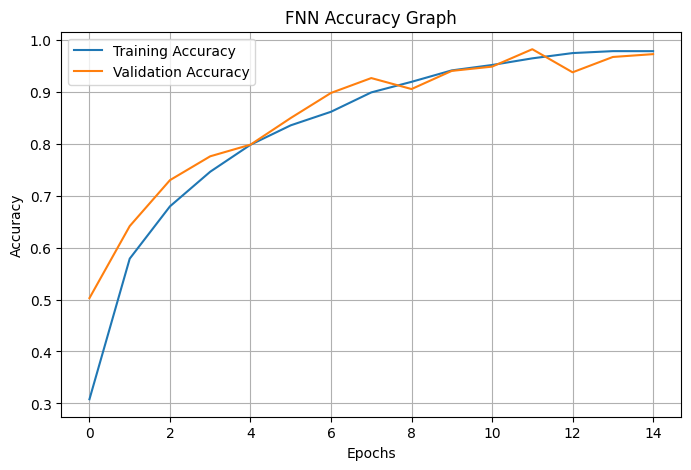

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title("FNN Accuracy Graph")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid()
plt.show()

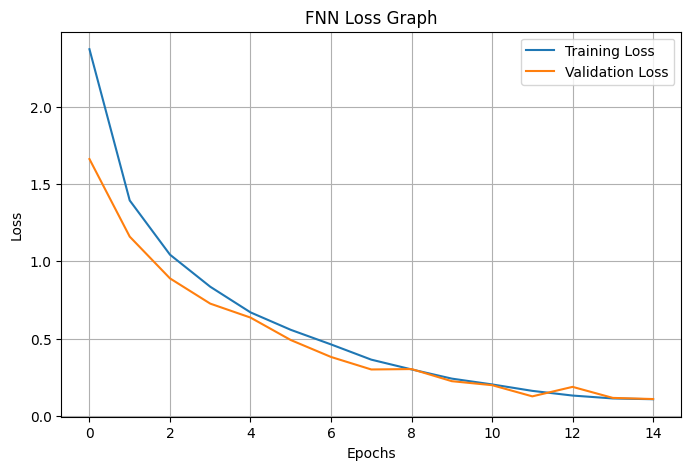

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("FNN Loss Graph")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid()
plt.show()

In [14]:
predictions = model.predict(X_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

actual_letters = encoder.inverse_transform(y_test[:5])
predicted_letters = encoder.inverse_transform(predicted_labels)

for i in range(5):
    print("Actual Letter:", actual_letters[i])
    print("Predicted Letter:", predicted_letters[i])
    print("-------------------------")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Actual Letter: 6
Predicted Letter: 6
-------------------------
Actual Letter: 5
Predicted Letter: 5
-------------------------
Actual Letter: 10
Predicted Letter: 10
-------------------------
Actual Letter: 0
Predicted Letter: 0
-------------------------
Actual Letter: 3
Predicted Letter: 3
-------------------------


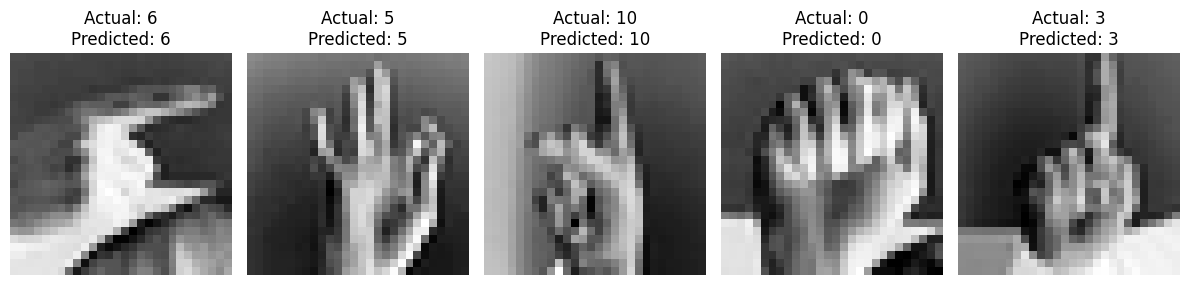

In [16]:
plt.figure(figsize=(12, 5))

for i in range(5):

    plt.subplot(1, 5, i+1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='Greys')

    plt.title(
        f"Actual: {actual_letters[i]}\nPredicted: {predicted_letters[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


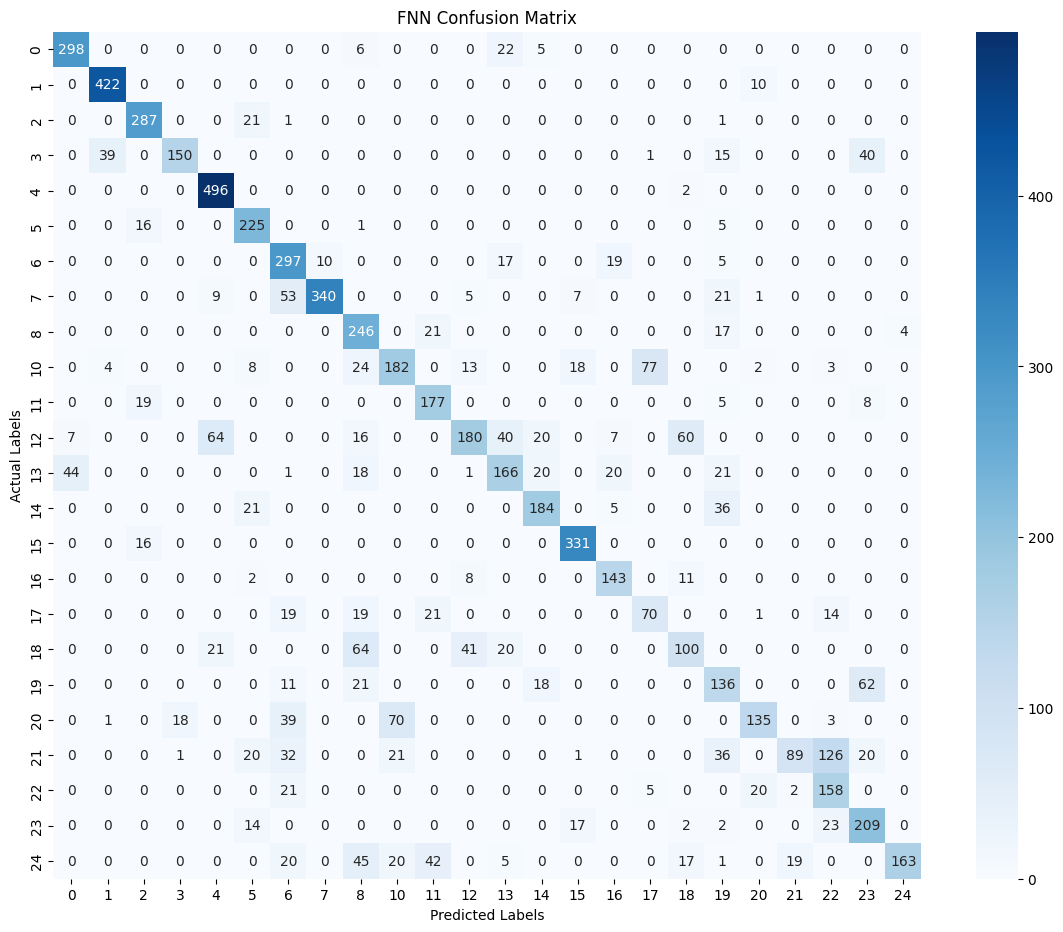

In [17]:
y_pred = model.predict(X_test)

y_pred_labels = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_labels)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=encoder.classes_,
    yticklabels=encoder.classes_
)

plt.title("FNN Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("Actual Labels")

plt.show()

In [18]:
print(classification_report(
    y_test,
    y_pred_labels,
    target_names=[str(x) for x in encoder.classes_]
))

              precision    recall  f1-score   support

           0       0.85      0.90      0.88       331
           1       0.91      0.98      0.94       432
           2       0.85      0.93      0.89       310
           3       0.89      0.61      0.72       245
           4       0.84      1.00      0.91       498
           5       0.72      0.91      0.81       247
           6       0.60      0.85      0.71       348
           7       0.97      0.78      0.87       436
           8       0.53      0.85      0.66       288
          10       0.62      0.55      0.58       331
          11       0.68      0.85      0.75       209
          12       0.73      0.46      0.56       394
          13       0.61      0.57      0.59       291
          14       0.74      0.75      0.75       246
          15       0.89      0.95      0.92       347
          16       0.74      0.87      0.80       164
          17       0.46      0.49      0.47       144
          18       0.52    